# Predikcia dojazdu elektrických áut: finálne vyhodnotenie

V `ladenie.ipynb` vyhral vyladený **Gradient Boosting** s chybou ~16 km v krížovej validácii.
Teraz ho prvýkrát a **iba raz** vyhodnotíme na testovacích dátach. Je to 317 áut, ktoré pri
výbere ani ladení modelu nikto nevidel.

Prečo iba raz: keby sme sa podľa výsledku na teste vrátili a model ešte upravovali, test by sa
stal ďalšou validáciou a stratili by sme nestranný odhad toho, ako model zvládne nové autá.

## 1. Príprava dát

Rovnaké kroky ako v predchádzajúcich notebookoch, s rovnakým rozdelením na tréning a test.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

data = pd.read_csv('data/ev_clean.csv')
y = data['range_km']
X = data.drop(columns='range_km')

num_col = X.select_dtypes(include='number').columns.tolist()
cat_col = X.select_dtypes(exclude='number').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, random_state=42)

prep_stromy = ColumnTransformer([
    ('num', 'passthrough', num_col),
    ('cat', OneHotEncoder(min_frequency=10, handle_unknown='infrequent_if_exist',
                          sparse_output=False), cat_col),
])

print('Tréning:', X_train.shape, ' Test:', X_test.shape)

Tréning: (1268, 8)  Test: (317, 8)


Pri rozbore chýb chceme vidieť aj názvy áut. Stĺpec `model` sme v `analyza.ipynb` z dát odstránili,
lebo pre model je to iba identifikátor. V pôvodnom súbore `ev_epa.csv` ho však máme. Čistenie iba
vyhodilo autá spred roku 2011 a poradie riadkov nemenilo, takže názvy vieme priradiť podľa poradia.
`assert` overí, že riadky naozaj sedia. Ak by nesedeli, skončí chybou.

In [2]:
epa = pd.read_csv('data/ev_epa.csv')
nazvy = epa[epa['year'] >= 2011].reset_index(drop=True)

kontrola = ['year', 'make', 'kwh_per_100km', 'range_km']
assert (nazvy[kontrola].values == data[kontrola].values).all(), 'riadky nesedia'
nazvy = nazvy['model']
print('Názvy áut priradené:', len(nazvy))

Názvy áut priradené: 1585


## 2. Finálny model

Hyperparametre preberáme z jemnej mriežky v `ladenie.ipynb`. `GridSearchCV` tu nespúšťame znova,
trvalo by to niekoľko minút a výsledok by bol rovnaký.

Model natrénujeme na **všetkých** trénovacích dátach (1268 áut). Pri krížovej validácii sa vždy
učil iba na 4/5 z nich.

In [3]:
from sklearn.ensemble import GradientBoostingRegressor

model = Pipeline([
    ('prep', prep_stromy),
    ('model', GradientBoostingRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=7,
        min_samples_leaf=1,
        subsample=0.8,
        random_state=42,
    )),
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['year','make','vehicle_class',...,'n_motors','charge_time_240v_hr', 'kwh_per_100km']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of col

## 3. Výsledok na testovacích dátach

Rovnaké metriky ako doteraz: MAE, RMSE a R². Pre porovnanie pridáme baseline (tipovanie priemeru
z tréningu) a odhad z krížovej validácie.

In [4]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

predikcia = pd.Series(model.predict(X_test), index=X_test.index)
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train).predict(X_test)

def metriky(skutocne, predpovedane):
    return {
        'MAE': mean_absolute_error(skutocne, predpovedane),
        'RMSE': root_mean_squared_error(skutocne, predpovedane),
        'R2': r2_score(skutocne, predpovedane),
    }

pd.DataFrame({
    'Gradient Boosting (test)': metriky(y_test, predikcia),
    'Baseline (test)': metriky(y_test, baseline),
}).T.round(3)

,MAE,RMSE,R2
Gradient Boosting (test),15.536,32.486,0.933
Baseline (test),89.680,125.800,-0.000


- **MAE ~15,5 km** na teste je dokonca o niečo lepšie ako odhad z krížovej validácie (16,2 km).
  Odhad z ladenia teda nebol prehnane optimistický a model funguje aj na nových autách.
- **R² ~0,93:** model vysvetlí 93 % rozptylu dojazdu.
- Baseline sa na teste mýli o ~90 km, model teda chybu znížil asi šesťnásobne.
- **RMSE (~32 km) je dvojnásobok MAE.** To naznačuje, že väčšina predpovedí je veľmi presná,
  ale niekoľko áut má veľkú chybu. Pozrieme sa na ne.

## 4. Predpovedaný vs. skutočný dojazd

Každý bod je jedno testovacie auto. Keby bol model dokonalý, všetky body by ležali na šedej
uhlopriečke. Bod nad ňou znamená, že model dojazd nadhodnotil, bod pod ňou, že ho podhodnotil.

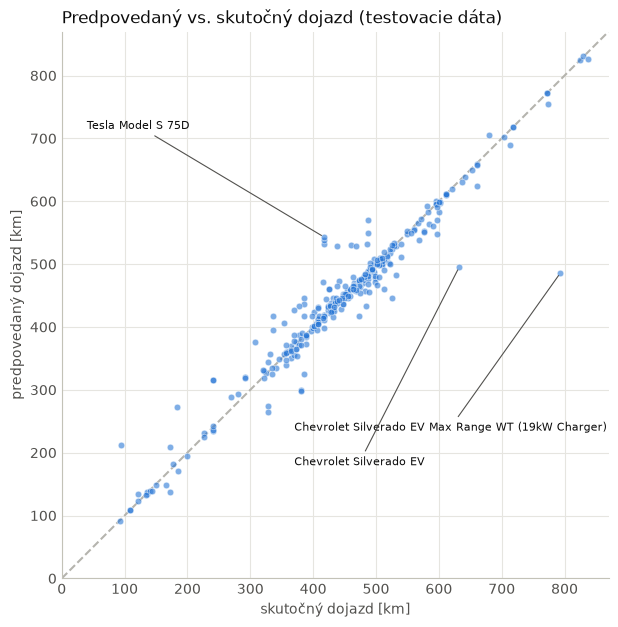

In [5]:
MODRA, SIVA = '#2a78d6', '#b5b4ae'
TEXT, TEXT_2, MRIEZKA = '#0b0b0b', '#52514e', '#e6e5e0'

def uprav_osi(ax):
    ax.tick_params(colors=TEXT_2, length=0)
    ax.set_axisbelow(True)
    for strana in ['top', 'right']:
        ax.spines[strana].set_visible(False)
    for strana in ['bottom', 'left']:
        ax.spines[strana].set_color('#c3c2b7')

chyba = predikcia - y_test

fig, ax = plt.subplots(figsize=(6.5, 6.5))
hranice = [0, 870]
ax.plot(hranice, hranice, color=SIVA, linewidth=1.5, linestyle='--', zorder=1)
ax.scatter(y_test, predikcia, s=22, color=MODRA, alpha=0.6, edgecolor='white', linewidth=0.5, zorder=2)

# popíšeme 3 autá s najväčšou chybou, popisy dáme do prázdnych rohov grafu
pod, nad = 0, 0
for idx in chyba.abs().nlargest(3).index:
    if chyba[idx] < 0:    # podhodnotené: bod je pod uhlopriečkou, popis vpravo dole
        pozicia = (370, 240 - 55 * pod)
        pod += 1
    else:                 # nadhodnotené: bod je nad uhlopriečkou, popis vľavo hore
        pozicia = (40, 720 - 55 * nad)
        nad += 1
    ax.annotate(f'{X_test.loc[idx, "make"]} {nazvy[idx]}', xy=(y_test[idx], predikcia[idx]),
                xytext=pozicia, fontsize=8, color=TEXT, va='center',
                arrowprops={'arrowstyle': '-', 'color': TEXT_2, 'linewidth': 0.8})

ax.set_xlim(hranice)
ax.set_ylim(hranice)
ax.set_aspect('equal')
ax.set_title('Predpovedaný vs. skutočný dojazd (testovacie dáta)', loc='left', color=TEXT)
ax.set_xlabel('skutočný dojazd [km]', color=TEXT_2)
ax.set_ylabel('predpovedaný dojazd [km]', color=TEXT_2)
ax.grid(color=MRIEZKA, linewidth=0.8)
uprav_osi(ax)
plt.tight_layout()
plt.show()

### 4.1 Ako sú chyby rozložené

Chyba je `predikcia − skutočnosť`. Kladná chyba znamená, že model dojazd nadhodnotil, záporná,
že ho podhodnotil.

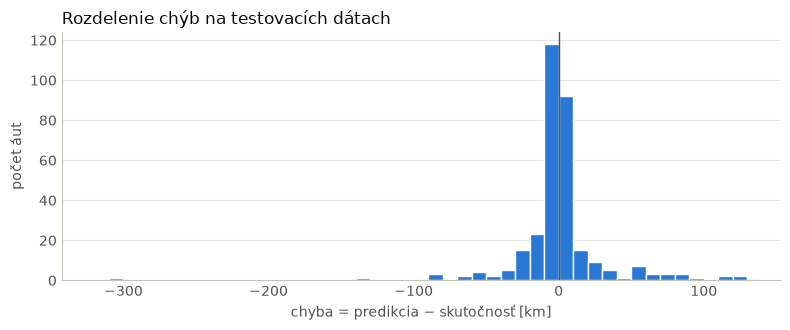

Priemerná chyba (posun):        +0.5 km
Medián absolútnej chyby:        5.0 km
Autá s chybou do 25 km:         83%
Autá s chybou do 10 % dojazdu:  88%
90 % áut má chybu menšiu ako:   50 km


In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(chyba, bins=range(-320, 140, 10), color=MODRA, edgecolor='white', linewidth=1)
ax.axvline(0, color=TEXT_2, linewidth=1)
ax.set_title('Rozdelenie chýb na testovacích dátach', loc='left', color=TEXT)
ax.set_xlabel('chyba = predikcia − skutočnosť [km]', color=TEXT_2)
ax.set_ylabel('počet áut', color=TEXT_2)
ax.grid(axis='y', color=MRIEZKA, linewidth=0.8)
uprav_osi(ax)
plt.tight_layout()
plt.show()

abs_chyba = chyba.abs()
print(f'Priemerná chyba (posun):        {chyba.mean():+.1f} km')
print(f'Medián absolútnej chyby:        {abs_chyba.median():.1f} km')
print(f'Autá s chybou do 25 km:         {(abs_chyba <= 25).mean():.0%}')
print(f'Autá s chybou do 10 % dojazdu:  {(abs_chyba / y_test <= 0.1).mean():.0%}')
print(f'90 % áut má chybu menšiu ako:   {abs_chyba.quantile(0.9):.0f} km')

- **Priemerná chyba je takmer 0.** Model systematicky nenadhodnocuje ani nepodhodnocuje.
- **Medián absolútnej chyby je iba ~5 km.** Pre typické auto je predpoveď veľmi presná.
  Priemer (MAE ~15 km) zvyšuje niekoľko áut s veľkou chybou, preto je MAE oveľa väčšie ako medián.
- Takmer 9 z 10 áut má chybu do 10 % dojazdu.

## 5. Autá s najväčšou chybou

In [7]:
rozbor = X_test.copy()
rozbor.insert(2, 'model', nazvy[X_test.index])
rozbor['skutočný'] = y_test
rozbor['predikcia'] = predikcia.round(0)
rozbor['chyba'] = chyba.round(0)

stlpce = ['year', 'make', 'model', 'motor_kw', 'charge_time_240v_hr', 'kwh_per_100km',
          'skutočný', 'predikcia', 'chyba']
rozbor.loc[abs_chyba.nlargest(10).index, stlpce].reset_index(drop=True)

,year,make,model,motor_kw,charge_time_240v_hr,kwh_per_100km,skutočný,predikcia,chyba
0,2026,Chevrolet,Silverado EV Max Range WT (19kW Charger),511.0,13.8,30.75,793.0,485.0,-308.0
1,2024,Chevrolet,Silverado EV,378.0,11.0,31.40,632.0,495.0,-137.0
2,2018,Tesla,Model S 75D,386.0,12.0,20.27,417.0,543.0,126.0
3,2017,Tesla,Model S AWD - 75D,386.0,12.0,20.51,417.0,538.0,121.0
4,2021,Kandi,K27,20.0,7.0,18.35,95.0,212.0,117.0
5,2019,Tesla,Model S 75D,386.0,12.0,20.27,417.0,532.0,115.0
6,2024,Tesla,Model 3 RWD,192.0,10.5,15.81,438.0,528.0,90.0
7,2024,MINI,Cooper SE Hardtop 2 door,135.0,4.0,19.08,183.0,273.0,90.0
8,2026,Tesla,Model Y Standard RWD (19in Wheels),243.0,10.0,15.96,488.0,570.0,82.0
9,2025,Vinfast,VF 7 Plus,416.0,12.0,27.57,336.0,418.0,82.0


Z najväčších chýb vidno, kde má model slabé miesta:

- **Chýba mu kapacita batérie.** Dojazd je v podstate kapacita batérie / spotreba. Spotrebu model
  pozná (`kwh_per_100km`), kapacitu batérie však v dátach nemáme. Model ju odhaduje nepriamo
  z času nabíjania (`charge_time_240v_hr`): väčšia batéria sa nabíja dlhšie.
- **Čas nabíjania však závisí aj od nabíjačky.** Chevrolet Silverado EV Max Range má obrovskú batériu,
  no má 19 kW nabíjačku (v názve „19kW Charger“), takže sa nabije relatívne rýchlo. Model z času
  nabíjania usúdil na menšiu batériu a dojazd podhodnotil o ~300 km.
- **Tesla Model S 75D:** v dátach majú všetky verzie Model S a Model X s batériou od 60 do 100 kWh
  rovnaký výkon (386 kW) aj čas nabíjania (12 h), hoci dojazd majú od 322 do 539 km. Číslo v názve
  (75D, 100D) je práve kapacita batérie, model ho však nevidí. Verzie od seba nevie odlíšiť a 75D
  odhadol skoro ako 100D.
- **Zriedkavé značky (Kandi, MINI):** v tréningu sú iba v zlúčenej kategórii `infrequent`, model
  o nich vie málo.

### 5.1 Chyba podľa dojazdu

Kde sa model mýli najviac: pri autách s malým, stredným alebo veľkým dojazdom?

In [8]:
pasma = pd.cut(y_test, bins=[0, 250, 400, 500, 600, 900],
               labels=['do 250 km', '250–400 km', '400–500 km', '500–600 km', 'nad 600 km'])
abs_chyba.groupby(pasma, observed=True).agg(['count', 'mean', 'median']).rename(
    columns={'count': 'počet áut', 'mean': 'MAE', 'median': 'medián chyby'}).round(1)

,počet áut,MAE,medián chyby
range_km,,,
do 250 km,26,19.7,4.4
250–400 km,61,20.7,9.5
400–500 km,142,13.0,4.2
500–600 km,62,11.6,5.4
nad 600 km,26,22.8,1.7


Najpresnejší je model pri autách s dojazdom 400–600 km. Takých je v dátach najviac a model sa na
nich naučil najlepšie. Na okrajoch (do 250 km a nad 600 km) je MAE väčšie, ale medián chyby zostáva
malý. Priemer tam zvyšuje niekoľko áut s veľkou chybou, napríklad Silverado nad 600 km.
Najväčší medián chyby má pásmo 250–400 km, kde sa model mýli o niečo častejšie.

### 5.2 Autá s „dvojčaťom“ v tréningu

V `modely.ipynb` sme našli autá s úplne rovnakými príznakmi. Niektoré testovacie autá majú
dvojča v tréningu. Pri nich model nemusí predpovedať, stačí, že si dvojča zapamätal.
Ako presný je model pri autách, ktoré naozaj nikdy nevidel?

In [9]:
kluc_train = set(X_train.astype(str).agg('|'.join, axis=1))
ma_dvojca = X_test.astype(str).agg('|'.join, axis=1).isin(kluc_train)

pd.DataFrame({
    'počet áut': ma_dvojca.value_counts(),
    'MAE': abs_chyba.groupby(ma_dvojca).mean().round(1),
}).rename(index={True: 'má dvojča v tréningu', False: 'bez dvojčaťa'})

,počet áut,MAE
bez dvojčaťa,284,16.5
má dvojča v tréningu,33,7.4


Pri autách s dvojčaťom v tréningu je chyba iba ~7 km, pri autách bez neho ~16,5 km.
To je **poctivý odhad pre úplne nové auto** a zhoduje sa s výsledkom `GroupKFold` z ladenia (~17 km).

## 6. Ktoré príznaky model používa najviac

**Permutation importance** funguje takto: vezmeme jeden príznak (napríklad `year`), jeho hodnoty
v testovacích dátach náhodne pomiešame medzi autami a zmeriame, o koľko sa zhorší MAE. Keď model
príznak nepotrebuje, chyba sa nezmení. Keď sa naň spolieha, chyba výrazne vzrastie. Miešanie sa
opakuje 10-krát (`n_repeats=10`) a čiarka v grafe je smerodajná odchýlka.

Výhoda: meria celý pôvodný príznak (napríklad `make`) naraz, nie každý one-hot stĺpec zvlášť.

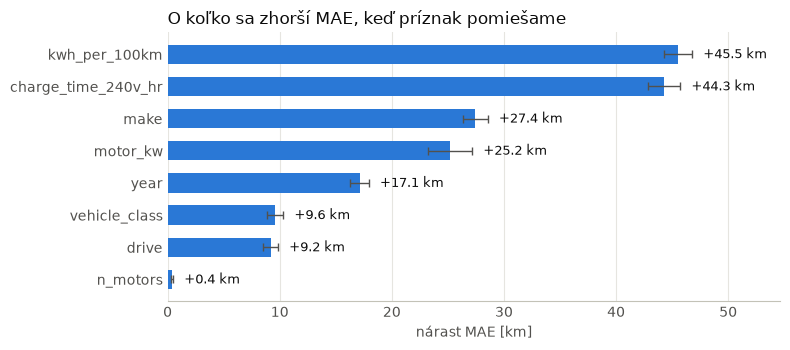

In [10]:
from sklearn.inspection import permutation_importance

dolezitost = permutation_importance(model, X_test, y_test, scoring='neg_mean_absolute_error',
                                    n_repeats=10, random_state=42, n_jobs=-1)
dolezitost = pd.DataFrame({
    'nárast MAE': dolezitost.importances_mean,
    'std': dolezitost.importances_std,
}, index=X_test.columns).sort_values('nárast MAE')

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(dolezitost.index, dolezitost['nárast MAE'], xerr=dolezitost['std'], height=0.6, color=MODRA,
        error_kw={'ecolor': TEXT_2, 'elinewidth': 1, 'capsize': 3})
for i, (hodnota, std) in enumerate(zip(dolezitost['nárast MAE'], dolezitost['std'])):
    ax.text(hodnota + std + 1, i, f'+{hodnota:.1f} km', va='center', color=TEXT, fontsize=9)
ax.set_title('O koľko sa zhorší MAE, keď príznak pomiešame', loc='left', color=TEXT)
ax.set_xlabel('nárast MAE [km]', color=TEXT_2)
ax.set_xlim(0, dolezitost['nárast MAE'].max() * 1.2)
ax.grid(axis='x', color=MRIEZKA, linewidth=0.8)
uprav_osi(ax)
ax.spines['left'].set_visible(False)
plt.tight_layout()
plt.show()

- **Spotreba (`kwh_per_100km`)** je najdôležitejší príznak, hoci v analýze mala s dojazdom takmer
  nulovú koreláciu. Presne to sme v `analyza.ipynb` predpokladali: korelácia meria iba priamy
  lineárny vzťah. Spotreba ovplyvňuje dojazd až v kombinácii s veľkosťou batérie.
- **Čas nabíjania** je takmer rovnako dôležitý, lebo nahrádza chýbajúcu kapacitu batérie.
- **Počet motorov (`n_motors`)** model takmer nepoužíva. Rovnakú informáciu nesie výkon motora
  a pohon, ako sme videli už v analýze.

## 7. Zhrnutie projektu

| Krok | Notebook | Výsledok |
|---|---|---|
| Analýza a čistenie | `analyza.ipynb` | 1585 áut od roku 2011, 8 príznakov |
| Preprocessing | `preprocessing.ipynb` | tréning/test 80/20, one-hot + škálovanie |
| Porovnanie modelov | `modely.ipynb` | Random Forest ~21 km, Gradient Boosting ~31 km |
| Ladenie | `ladenie.ipynb` | Gradient Boosting ~16 km |
| **Test** | `vyhodnotenie.ipynb` | **MAE ~15,5 km, R² ~0,93** |

Vyladený Gradient Boosting predpovedá dojazd elektrického auta s priemernou chybou ~15 km. Pre
typické auto je chyba iba ~5 km. Veľké chyby vznikajú hlavne pri autách, kde čas nabíjania dobre
nezodpovedá veľkosti batérie.

**Čo by model zlepšilo:** pridať **kapacitu batérie v kWh** z iného zdroja (dataset EPA ju neobsahuje)
alebo výkon palubnej nabíjačky, aby sa čas nabíjania dal správne prepočítať na veľkosť batérie.